In [1]:
import pickle
import numpy as np
import pandas as pd
from tqdm import tqdm
from utils import *
from concurrent.futures import ThreadPoolExecutor, as_completed

In [2]:
features = pd.read_csv('../Data/ratio_and_flag_features.csv')
features.head()

,id,data_type,default,HQ_city,ateco_sector,log_assets,net_profit_assets,operating_profit_assets,operating_margin,roa,...,cashflow_profit_gap_assets,sales_assets,receivables_assets,receivables_days_proxy,negative_equity,operating_loss,nonpositive_revenue,zero_financing_expense,sector_category,legal_structure_category
0,520288,oot2,0,28.0,14.0,14.481769,-0.041752,-0.038071,-0.137751,-3.81,...,-0.041316,0.276373,0.145363,191.978057,0.0,1.0,0.0,0.0,14.0,SRL
1,520288,train,0,28.0,14.0,14.546602,-0.051692,-0.027638,-0.059348,-2.76,...,-0.049824,0.465685,0.186610,146.263132,1.0,1.0,0.0,0.0,14.0,SRL
2,520288,train,0,28.0,14.0,14.496521,-0.039385,-0.021674,-0.067053,-2.17,...,-0.055893,0.323243,0.196500,221.884742,1.0,1.0,0.0,0.0,14.0,SRL
3,520288,train,0,28.0,14.0,14.385994,0.020763,0.062039,0.053771,6.20,...,-0.024479,1.153767,0.257316,81.403304,0.0,0.0,0.0,0.0,14.0,SRL
4,520288,oot1,0,28.0,14.0,14.456103,-0.044052,-0.040849,-0.137288,-4.08,...,-0.042943,0.297545,0.147763,181.261401,0.0,1.0,0.0,0.0,14.0,SRL


In [3]:
id_vars = ['id', 'data_type', 'HQ_city', 'ateco_sector']
target_var = 'default'
feature_vars = [col for col in features.columns if col not in id_vars + [target_var]]
categorical_features = ['legal_structure_category', 'sector_category']

In [4]:
train = features.query('data_type == "train"')
oot1 = features.query('data_type == "oot1"')
oot2 = features.query('data_type == "oot2"')

print(train.shape, oot1.shape, oot2.shape)

(475389, 30) (174229, 30) (183730, 30)


### Descriptive statistics

In [5]:
null_df = pd.DataFrame({'null': train[feature_vars].isna().sum(), 'null_rate': train[feature_vars].isna().sum()/train.shape[0]})
null_df.sort_values(by='null_rate', ascending=False)

,null,null_rate
roe,32106,0.067536
receivables_days_proxy,15853,0.033347
interest_coverage_proxy,15752,0.033135
operating_margin,15602,0.032819
cash_short_term_debt,970,0.002040
zero_financing_expense,282,0.000593
cashflow_liabilities_proxy,175,0.000368
sales_assets,105,0.000221
nonpositive_revenue,105,0.000221
operating_cashflow_assets,82,0.000172


In [6]:
features[feature_vars].describe().T

,count,mean,std,min,25%,50%,75%,max
log_assets,833348.0,1.530304e+01,9.449465e-01,1.422098e+01,14.590323,15.055894,15.757350,2.499498e+01
net_profit_assets,833328.0,7.564334e-03,1.152560e-01,-4.142001e+01,-0.005329,0.003173,0.020873,7.936417e+00
operating_profit_assets,833327.0,2.895161e-02,1.642964e+00,-1.307387e+03,0.002302,0.025338,0.053702,9.075597e+00
operating_margin,805336.0,-1.889987e+02,2.086579e+04,-9.022660e+06,0.009645,0.043877,0.121295,1.336039e+06
roa,833321.0,3.208671e+00,9.630633e+00,-9.639000e+02,0.230000,2.530000,5.370000,9.075600e+02
roe,777806.0,4.436697e+00,2.884659e+01,-1.500000e+02,-1.350000,2.710000,13.570000,1.499900e+02
working_capital_assets,833342.0,1.441584e-01,3.517325e-01,-5.614489e+01,-0.026842,0.101733,0.323164,5.343304e+00
cash_assets,833331.0,5.514149e-02,1.025718e-01,-1.378620e+00,0.001653,0.012453,0.059831,1.374420e+00
cash_short_term_debt,831632.0,4.062118e+00,8.393368e+02,-6.374071e+02,0.004526,0.036330,0.199695,6.219384e+05
liabilities_assets_proxy,833347.0,7.307228e-01,3.301206e-01,-4.011143e-01,0.572740,0.812689,0.944609,8.282863e+01


### Null imputation (nearest neighbour based)

In [7]:
features_to_impute = list(null_df.query('null > 0').index)
len(features_to_impute)

19

In [8]:
train_imputed = train.copy()
oot1_imputed = oot1.copy()
oot2_imputed = oot2.copy()

In [9]:
for feat in features_to_impute:
    print(feat)
    temp = nearest_neighbour_imputer(train_imputed, train, feat, distance_col='log_assets')
    train_imputed[feat] = temp

net_profit_assets


100%|██████████| 18/18 [00:00<00:00, 375.57it/s]


operating_profit_assets


100%|██████████| 19/19 [00:00<00:00, 1367.89it/s]


operating_margin


100%|██████████| 15602/15602 [00:00<00:00, 22469.57it/s]


... (28 outputs left out)

nonpositive_revenue


100%|██████████| 105/105 [00:00<00:00, 2354.25it/s]


zero_financing_expense


100%|██████████| 282/282 [00:00<00:00, 4133.88it/s]


In [10]:
for feat in features_to_impute:
    print(feat)
    temp = nearest_neighbour_imputer(oot1_imputed, oot1, feat, distance_col='log_assets')
    oot1_imputed[feat] = temp

net_profit_assets


100%|██████████| 1/1 [00:00<00:00, 1492.63it/s]


operating_profit_assets


0it [00:00, ?it/s]


operating_margin


100%|██████████| 6418/6418 [00:00<00:00, 22875.77it/s]


... (28 outputs left out)

nonpositive_revenue


100%|██████████| 63/63 [00:00<00:00, 2711.86it/s]


zero_financing_expense


100%|██████████| 76/76 [00:00<00:00, 3493.30it/s]


In [11]:
for feat in features_to_impute:
    print(feat)
    temp = nearest_neighbour_imputer(oot2_imputed, oot2, feat, distance_col='log_assets')
    oot2_imputed[feat] = temp

net_profit_assets


100%|██████████| 1/1 [00:00<00:00, 380.06it/s]


operating_profit_assets


100%|██████████| 2/2 [00:00<00:00, 433.45it/s]


operating_margin


100%|██████████| 5992/5992 [00:00<00:00, 21312.39it/s]


... (28 outputs left out)

nonpositive_revenue


100%|██████████| 3/3 [00:00<00:00, 1067.52it/s]


zero_financing_expense


100%|██████████| 4/4 [00:00<00:00, 1161.78it/s]


In [12]:
train_imputed.to_csv('../Data/train_imputed.csv', index=False)
oot1_imputed.to_csv('../Data/oot1_imputed.csv', index=False)
oot2_imputed.to_csv('../Data/oot2_imputed.csv', index=False)

train.to_csv('../Data/train.csv', index=False)
oot1.to_csv('../Data/oot1.csv', index=False)
oot2.to_csv('../Data/oot2.csv', index=False)

### compute IV (non-imputed)

In [13]:
feature_cols = [f for f in features.columns if f not in ['id','data_type','default']]
iv_df = []
for f in feature_cols:
    try:
        iv_train, iv_train_df = IV(train, f)
        iv_oot1, iv_oot1_df = IV(oot1, f)
        iv_oot2, iv_oot2_df = IV(oot2, f)
        iv_df.append([f, iv_train, iv_train_df, iv_oot1, iv_oot1_df, iv_oot2, iv_oot2_df])
    except:
        print(f'FAILED: {f}')
iv_df = pd.DataFrame(iv_df, columns=['features','iv_train','iv_train_df','iv_oot1','iv_oot1_df','iv_oot2','iv_oot2_df']).sort_values(by='iv_train', ascending=False)
iv_df.to_csv('../Files/iv_df.csv', index=False)

FAILED: legal_structure_category


In [14]:
least_important_features = iv_df.query('iv_train <= 0.02').sort_values('iv_train', ascending=False)[['features','iv_train', 'iv_train_df']]
display(least_important_features)
suspicious_features = iv_df.query('iv_train >= 0.5').sort_values('iv_train', ascending=False)[['features','iv_train', 'iv_train_df']]
display(suspicious_features)

,features,iv_train,iv_train_df
0,HQ_city,1.351647e-02,bins Goods Bads Goods (%) Bad...
2,log_assets,7.146279e-03,bins Goods Bads Goods (%) B...
22,operating_loss,1.286662e-04,bins Goods Bads Goods (%) Bad...
23,nonpositive_revenue,2.630087e-05,bins Goods Bads Goods (%) Bad...
24,zero_financing_expense,1.641188e-07,bins Goods Bads Goods (%) Bad...
21,negative_equity,2.197584e-12,bins Goods Bads Goods (%) Bad...


,features,iv_train,iv_train_df
16,cashflow_liabilities_proxy,0.820941,bins Goods Bads Goods (%...
7,roe,0.787642,bins Goods Bads Goods (%)...
3,net_profit_assets,0.778038,bins Goods Bads Goods (...
15,operating_cashflow_assets,0.774725,bins Goods Bads Goods (%...
11,liabilities_assets_proxy,0.621242,bins Goods Bads Goods (%) Ba...
12,equity_assets,0.621241,bins Goods Bads Goods (%) ...
4,operating_profit_assets,0.615308,bins Goods Bads Goods (...
6,roa,0.614279,bins Goods Bads Goods (%) ...
14,interest_coverage_proxy,0.555554,bins Goods Bads Goods...
5,operating_margin,0.507098,bins Goods Bads Goods...


In [15]:
display(least_important_features.query('features == "log_assets"').loc[:, ['features', 'iv_train']])
display(least_important_features.query('features == "log_assets"')['iv_train_df'].values[0])
display(precision_recall_by_bin(train, 'log_assets'))

,features,iv_train
2,log_assets,0.007146


,bins,Goods,Bads,Goods (%),Bads (%),WoE,IV_bin
0,"(14.22, 14.361]",46749,790,0.099734,0.118798,-0.174927,0.003335
1,"(14.361, 14.51]",46859,680,0.099968,0.102257,-0.022638,0.000052
2,"(14.51, 14.672]",46856,683,0.099962,0.102708,-0.027104,0.000074
3,"(14.672, 14.85]",46845,694,0.099938,0.104362,-0.043316,0.000192
4,"(14.85, 15.052]",46863,676,0.099977,0.101656,-0.016653,0.000028
5,"(15.052, 15.286]",46900,638,0.100056,0.095941,0.041990,0.000173
6,"(15.286, 15.576]",46895,644,0.100045,0.096844,0.032523,0.000104
7,"(15.576, 15.963]",46888,651,0.100030,0.097896,0.021563,0.000046
8,"(15.963, 16.569]",46902,637,0.100060,0.095791,0.043601,0.000186
9,"(16.569, 24.995]",46982,557,0.100231,0.083761,0.179508,0.002956


,bin,records,defaults,population (%),precision (%),recall (%),cumm_precision (%),cumm_recall (%),lift
0,"(14.22, 14.361]",47539,790,10.00%,1.66%,11.88%,1.66%,11.88%,1.188
1,"(14.361, 14.51]",47539,680,10.00%,1.43%,10.23%,1.55%,22.11%,1.105
2,"(14.51, 14.672]",47539,683,10.00%,1.44%,10.27%,1.51%,32.38%,1.079
3,"(14.672, 14.85]",47539,694,10.00%,1.46%,10.44%,1.50%,42.81%,1.070
4,"(14.85, 15.052]",47539,676,10.00%,1.42%,10.17%,1.48%,52.98%,1.060
5,"(15.052, 15.286]",47538,638,10.00%,1.34%,9.59%,1.46%,62.57%,1.043
6,"(15.286, 15.576]",47539,644,10.00%,1.35%,9.68%,1.44%,72.26%,1.032
7,"(15.576, 15.963]",47539,651,10.00%,1.37%,9.79%,1.43%,82.05%,1.026
8,"(15.963, 16.569]",47539,637,10.00%,1.34%,9.58%,1.42%,91.62%,1.018
9,"(16.569, 24.995]",47539,557,10.00%,1.17%,8.38%,1.40%,100.00%,1.000


Feature: cashflow_liabilities_proxy, IV: 0.8209413051412254


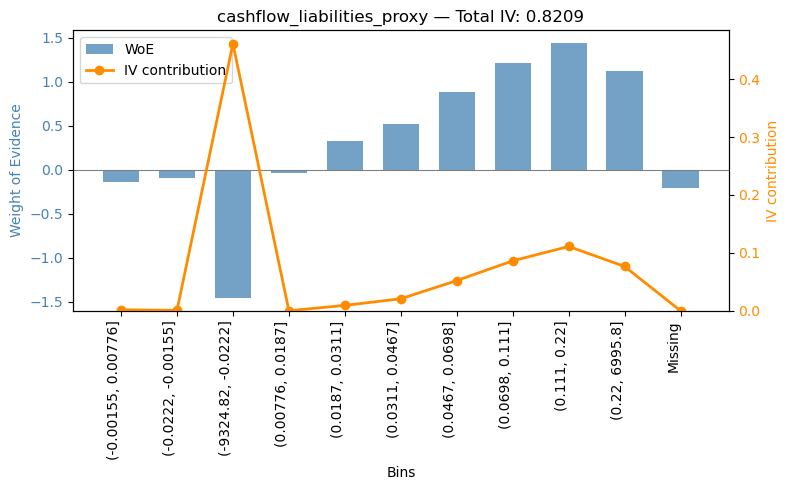

,bin,records,defaults,population (%),precision (%),recall (%),cumm_precision (%),cumm_recall (%),lift
0,"(-9324.82, -0.0222]",47522,2736,10.00%,5.76%,41.14%,5.76%,41.14%,4.116
1,"(-0.0222, -0.00155]",47521,729,10.00%,1.53%,10.96%,3.65%,52.11%,2.606
2,"(-0.00155, 0.00776]",47521,759,10.00%,1.60%,11.41%,2.96%,63.52%,2.118
3,"(0.00776, 0.0187]",47522,692,10.00%,1.46%,10.41%,2.59%,73.92%,1.849
4,"(0.0187, 0.0311]",47521,479,10.00%,1.01%,7.20%,2.27%,81.13%,1.623
5,"(0.0311, 0.0467]",47521,399,10.00%,0.84%,6.00%,2.03%,87.13%,1.453
6,"(0.0467, 0.0698]",47522,277,10.00%,0.58%,4.17%,1.83%,91.29%,1.305
7,"(0.0698, 0.111]",47521,199,10.00%,0.42%,2.99%,1.65%,94.29%,1.179
8,"(0.111, 0.22]",47521,159,10.00%,0.33%,2.39%,1.50%,96.68%,1.075
9,"(0.22, 6995.8]",47522,218,10.00%,0.46%,3.28%,1.40%,99.95%,1.000


Feature: roe, IV: 0.7876415534947192


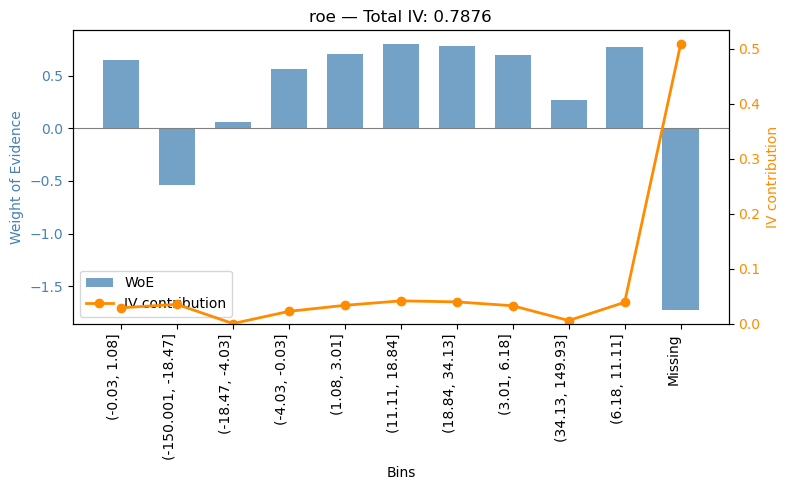

,bin,records,defaults,population (%),precision (%),recall (%),cumm_precision (%),cumm_recall (%),lift
0,"(-150.001, -18.47]",44330,1050,9.32%,2.37%,15.79%,2.37%,15.79%,1.693
1,"(-18.47, -4.03]",44381,588,9.34%,1.32%,8.84%,1.85%,24.63%,1.320
2,"(-4.03, -0.03]",44289,356,9.32%,0.80%,5.35%,1.50%,29.98%,1.072
3,"(-0.03, 1.08]",44488,328,9.36%,0.74%,4.93%,1.31%,34.92%,0.935
4,"(1.08, 3.01]",44266,308,9.31%,0.70%,4.63%,1.19%,39.55%,0.848
5,"(3.01, 6.18]",44262,311,9.31%,0.70%,4.68%,1.11%,44.23%,0.790
6,"(6.18, 11.11]",44334,289,9.33%,0.65%,4.35%,1.04%,48.57%,0.744
7,"(11.11, 18.84]",44316,280,9.32%,0.63%,4.21%,0.99%,52.78%,0.707
8,"(18.84, 34.13]",44297,286,9.32%,0.65%,4.30%,0.95%,57.08%,0.680
9,"(34.13, 149.93]",44320,477,9.32%,1.08%,7.17%,0.96%,64.26%,0.689


Feature: net_profit_assets, IV: 0.778038412590097


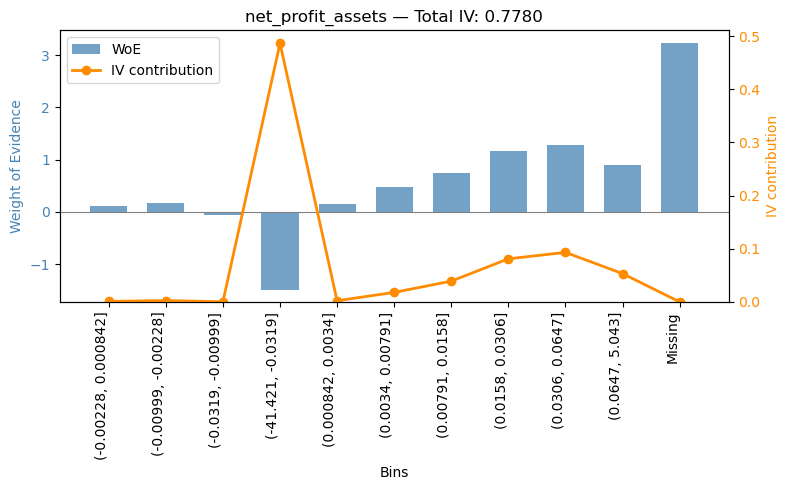

,bin,records,defaults,population (%),precision (%),recall (%),cumm_precision (%),cumm_recall (%),lift
0,"(-41.421, -0.0319]",47538,2809,10.00%,5.91%,42.24%,5.91%,42.24%,4.224
1,"(-0.0319, -0.00999]",47537,709,10.00%,1.49%,10.66%,3.70%,52.90%,2.645
2,"(-0.00999, -0.00228]",47537,562,10.00%,1.18%,8.45%,2.86%,61.35%,2.045
3,"(-0.00228, 0.000842]",47537,597,10.00%,1.26%,8.98%,2.46%,70.33%,1.758
4,"(0.000842, 0.0034]",47537,568,10.00%,1.19%,8.54%,2.21%,78.87%,1.578
5,"(0.0034, 0.00791]",47537,416,10.00%,0.88%,6.26%,1.98%,85.13%,1.419
6,"(0.00791, 0.0158]",47537,319,10.00%,0.67%,4.80%,1.80%,89.92%,1.285
7,"(0.0158, 0.0306]",47537,209,10.00%,0.44%,3.14%,1.63%,93.07%,1.163
8,"(0.0306, 0.0647]",47537,187,10.00%,0.39%,2.81%,1.49%,95.88%,1.065
9,"(0.0647, 5.043]",47537,274,10.00%,0.58%,4.12%,1.40%,100.00%,1.000


Feature: operating_cashflow_assets, IV: 0.7747245116514192


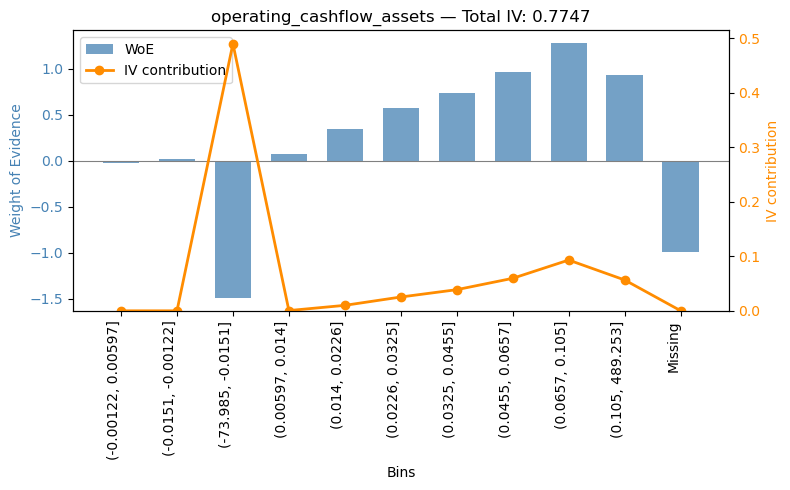

,bin,records,defaults,population (%),precision (%),recall (%),cumm_precision (%),cumm_recall (%),lift
0,"(-73.985, -0.0151]",47531,2819,10.00%,5.93%,42.39%,5.93%,42.39%,4.240
1,"(-0.0151, -0.00122]",47531,650,10.00%,1.37%,9.77%,3.65%,52.17%,2.609
2,"(-0.00122, 0.00597]",47530,682,10.00%,1.43%,10.26%,2.91%,62.42%,2.081
3,"(0.00597, 0.014]",47531,618,10.00%,1.30%,9.29%,2.51%,71.71%,1.793
4,"(0.014, 0.0226]",47531,473,10.00%,1.00%,7.11%,2.21%,78.83%,1.577
5,"(0.0226, 0.0325]",47530,376,10.00%,0.79%,5.65%,1.97%,84.48%,1.408
6,"(0.0325, 0.0455]",47531,320,10.00%,0.67%,4.81%,1.78%,89.29%,1.276
7,"(0.0455, 0.0657]",47530,257,10.00%,0.54%,3.86%,1.63%,93.16%,1.165
8,"(0.0657, 0.105]",47531,187,10.00%,0.39%,2.81%,1.49%,95.97%,1.067
9,"(0.105, 489.253]",47531,265,10.00%,0.56%,3.98%,1.40%,99.95%,1.000


Feature: liabilities_assets_proxy, IV: 0.6212417927236698


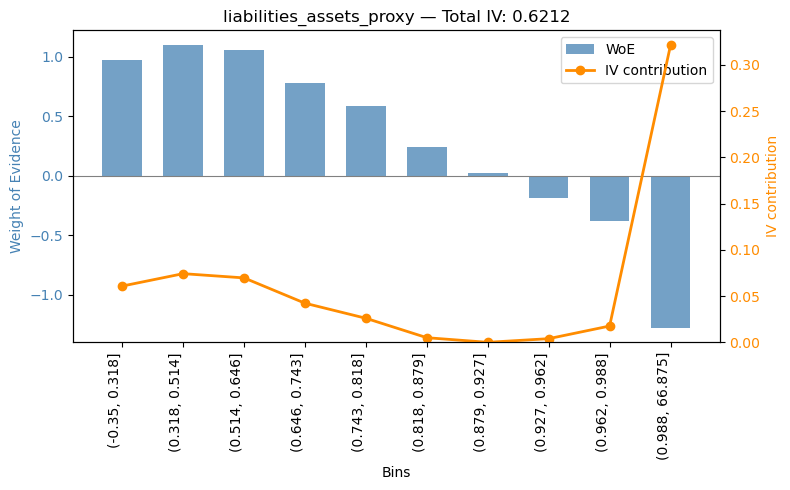

,bin,records,defaults,population (%),precision (%),recall (%),cumm_precision (%),cumm_recall (%),lift
0,"(-0.35, 0.318]",47539,254,10.00%,0.53%,3.82%,0.53%,3.82%,0.382
1,"(0.318, 0.514]",47539,223,10.00%,0.47%,3.35%,0.50%,7.17%,0.359
2,"(0.514, 0.646]",47539,233,10.00%,0.49%,3.50%,0.50%,10.68%,0.356
3,"(0.646, 0.743]",47539,308,10.00%,0.65%,4.63%,0.54%,15.31%,0.383
4,"(0.743, 0.818]",47539,373,10.00%,0.78%,5.61%,0.59%,20.92%,0.418
5,"(0.818, 0.879]",47538,526,10.00%,1.11%,7.91%,0.67%,28.83%,0.480
6,"(0.879, 0.927]",47539,653,10.00%,1.37%,9.82%,0.77%,38.65%,0.552
7,"(0.927, 0.962]",47539,802,10.00%,1.69%,12.06%,0.89%,50.71%,0.634
8,"(0.962, 0.988]",47539,968,10.00%,2.04%,14.56%,1.01%,65.26%,0.725
9,"(0.988, 66.875]",47539,2310,10.00%,4.86%,34.74%,1.40%,100.00%,1.000


Feature: equity_assets, IV: 0.6212405592543003


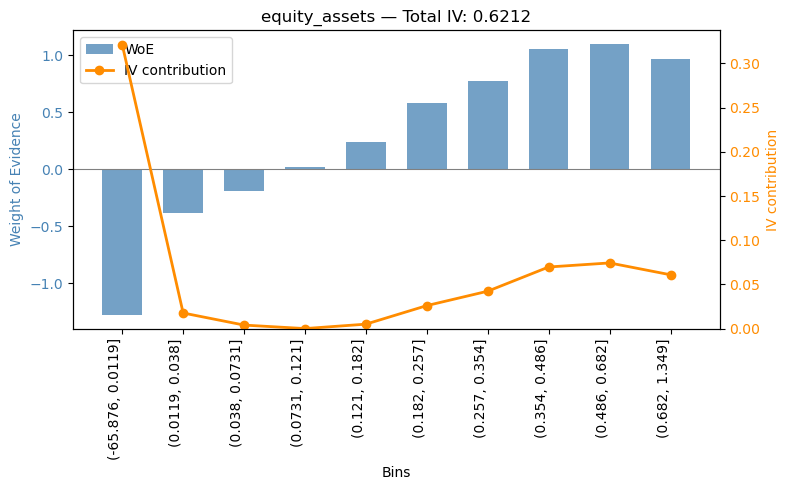

,bin,records,defaults,population (%),precision (%),recall (%),cumm_precision (%),cumm_recall (%),lift
0,"(-65.876, 0.0119]",47539,2310,10.00%,4.86%,34.74%,4.86%,34.74%,3.474
1,"(0.0119, 0.038]",47539,968,10.00%,2.04%,14.56%,3.45%,49.29%,2.465
2,"(0.038, 0.0731]",47539,802,10.00%,1.69%,12.06%,2.86%,61.35%,2.045
3,"(0.0731, 0.121]",47539,653,10.00%,1.37%,9.82%,2.49%,71.17%,1.779
4,"(0.121, 0.182]",47539,526,10.00%,1.11%,7.91%,2.21%,79.08%,1.582
5,"(0.182, 0.257]",47538,373,10.00%,0.78%,5.61%,1.97%,84.69%,1.412
6,"(0.257, 0.354]",47539,308,10.00%,0.65%,4.63%,1.79%,89.32%,1.276
7,"(0.354, 0.486]",47539,233,10.00%,0.49%,3.50%,1.62%,92.83%,1.160
8,"(0.486, 0.682]",47539,223,10.00%,0.47%,3.35%,1.49%,96.18%,1.069
9,"(0.682, 1.349]",47539,254,10.00%,0.53%,3.82%,1.40%,100.00%,1.000


Feature: operating_profit_assets, IV: 0.615308446499006


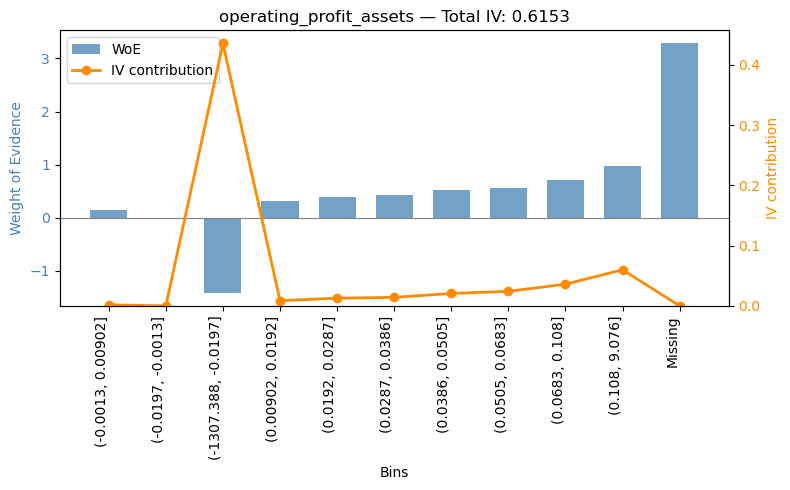

,bin,records,defaults,population (%),precision (%),recall (%),cumm_precision (%),cumm_recall (%),lift
0,"(-1307.388, -0.0197]",47537,2662,10.00%,5.60%,40.03%,5.60%,40.03%,4.003
1,"(-0.0197, -0.0013]",47537,671,10.00%,1.41%,10.09%,3.51%,50.12%,2.506
2,"(-0.0013, 0.00902]",47537,575,10.00%,1.21%,8.65%,2.74%,58.77%,1.959
3,"(0.00902, 0.0192]",47537,485,10.00%,1.02%,7.29%,2.31%,66.06%,1.652
4,"(0.0192, 0.0287]",47537,450,10.00%,0.95%,6.77%,2.04%,72.83%,1.457
5,"(0.0287, 0.0386]",47537,440,10.00%,0.93%,6.62%,1.85%,79.44%,1.324
6,"(0.0386, 0.0505]",47537,400,10.00%,0.84%,6.02%,1.71%,85.46%,1.221
7,"(0.0505, 0.0683]",47537,381,10.00%,0.80%,5.73%,1.59%,91.19%,1.140
8,"(0.0683, 0.108]",47537,330,10.00%,0.69%,4.96%,1.49%,96.15%,1.068
9,"(0.108, 9.076]",47537,256,10.00%,0.54%,3.85%,1.40%,100.00%,1.000


Feature: roa, IV: 0.614278805760833


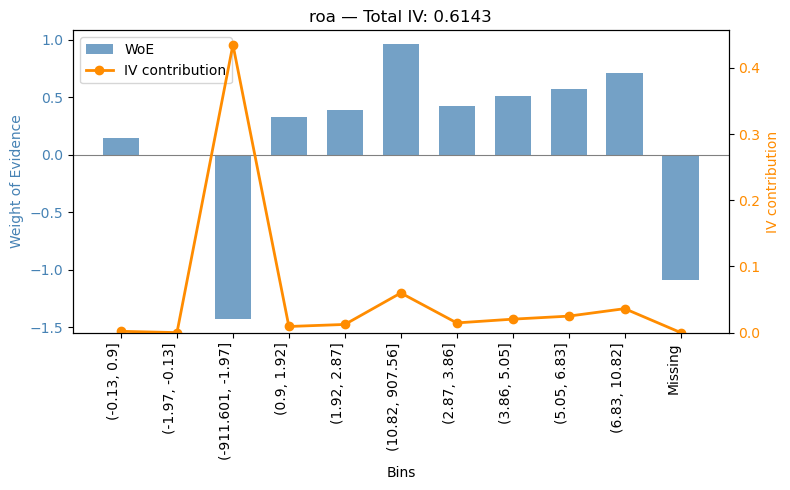

,bin,records,defaults,population (%),precision (%),recall (%),cumm_precision (%),cumm_recall (%),lift
0,"(-911.601, -1.97]",47625,2662,10.02%,5.59%,40.03%,5.59%,40.03%,3.996
1,"(-1.97, -0.13]",47760,672,10.05%,1.41%,10.11%,3.50%,50.14%,2.499
2,"(-0.13, 0.9]",47359,575,9.96%,1.21%,8.65%,2.74%,58.78%,1.958
3,"(0.9, 1.92]",47816,484,10.06%,1.01%,7.28%,2.31%,66.06%,1.648
4,"(1.92, 2.87]",47383,453,9.97%,0.96%,6.81%,2.04%,72.87%,1.456
5,"(2.87, 3.86]",47637,439,10.02%,0.92%,6.60%,1.85%,79.47%,1.323
6,"(3.86, 5.05]",47479,402,9.99%,0.85%,6.05%,1.71%,85.52%,1.221
7,"(5.05, 6.83]",47392,377,9.97%,0.80%,5.67%,1.59%,91.19%,1.139
8,"(6.83, 10.82]",47439,329,9.98%,0.69%,4.95%,1.49%,96.14%,1.068
9,"(10.82, 907.56]",47474,256,9.99%,0.54%,3.85%,1.40%,99.98%,1.000


Feature: interest_coverage_proxy, IV: 0.5555535041064982


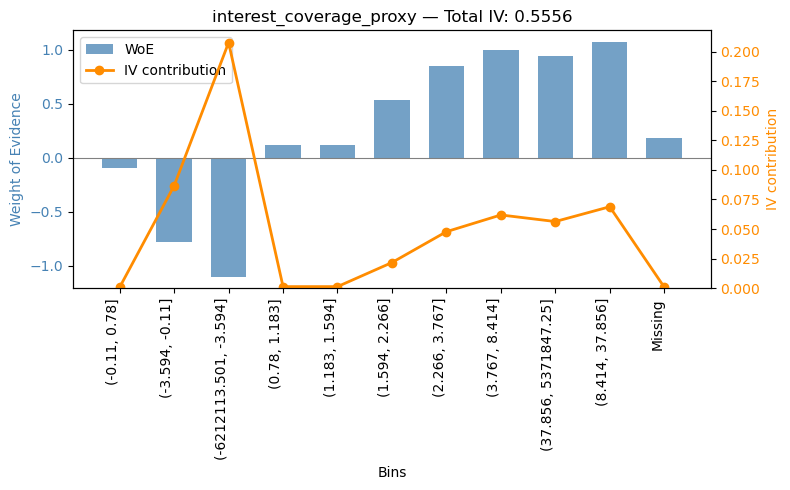

,bin,records,defaults,population (%),precision (%),recall (%),cumm_precision (%),cumm_recall (%),lift
0,"(-6212113.501, -3.594]",45964,1880,9.67%,4.09%,28.27%,4.09%,28.27%,2.924
1,"(-3.594, -0.11]",45964,1375,9.67%,2.99%,20.68%,3.54%,48.95%,2.531
2,"(-0.11, 0.78]",45963,705,9.67%,1.53%,10.60%,2.87%,59.55%,2.053
3,"(0.78, 1.183]",45964,570,9.67%,1.24%,8.57%,2.46%,68.12%,1.761
4,"(1.183, 1.594]",45964,570,9.67%,1.24%,8.57%,2.22%,76.69%,1.586
5,"(1.594, 2.266]",45963,378,9.67%,0.82%,5.68%,1.99%,82.38%,1.420
6,"(2.266, 3.767]",45964,276,9.67%,0.60%,4.15%,1.79%,86.53%,1.278
7,"(3.767, 8.414]",45963,238,9.67%,0.52%,3.58%,1.63%,90.11%,1.165
8,"(8.414, 37.856]",45964,222,9.67%,0.48%,3.34%,1.50%,93.44%,1.074
9,"(37.856, 5371847.25]",45964,252,9.67%,0.55%,3.79%,1.41%,97.23%,1.006


Feature: operating_margin, IV: 0.5070978756324289


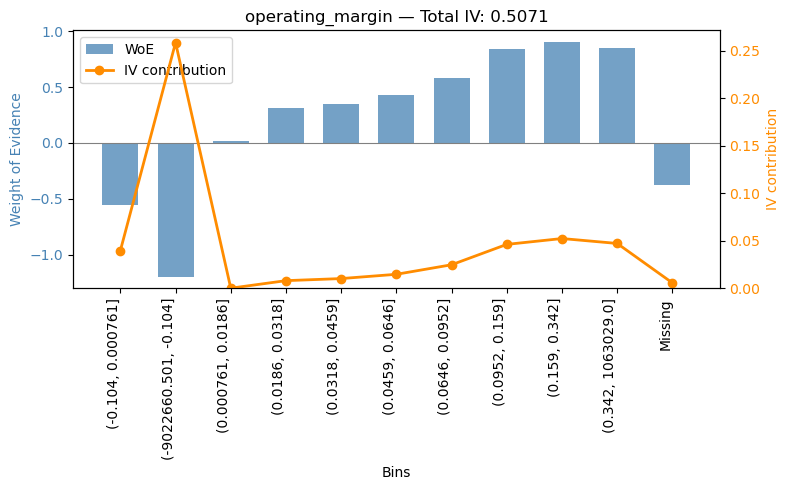

,bin,records,defaults,population (%),precision (%),recall (%),cumm_precision (%),cumm_recall (%),lift
0,"(-9022660.501, -0.104]",45979,2061,9.67%,4.48%,30.99%,4.48%,30.99%,3.204
1,"(-0.104, 0.000761]",45979,1110,9.67%,2.41%,16.69%,3.45%,47.68%,2.465
2,"(0.000761, 0.0186]",45978,630,9.67%,1.37%,9.47%,2.76%,57.16%,1.970
3,"(0.0186, 0.0318]",45979,474,9.67%,1.03%,7.13%,2.32%,64.29%,1.662
4,"(0.0318, 0.0459]",45979,454,9.67%,0.99%,6.83%,2.06%,71.11%,1.471
5,"(0.0459, 0.0646]",45978,420,9.67%,0.91%,6.32%,1.87%,77.43%,1.334
6,"(0.0646, 0.0952]",45979,363,9.67%,0.79%,5.46%,1.71%,82.89%,1.224
7,"(0.0952, 0.159]",45978,281,9.67%,0.61%,4.23%,1.57%,87.11%,1.126
8,"(0.159, 0.342]",45979,263,9.67%,0.57%,3.95%,1.46%,91.07%,1.046
9,"(0.342, 1063029.0]",45979,278,9.67%,0.60%,4.18%,1.38%,95.25%,0.985


In [16]:
for feats in suspicious_features['features']:
    print(f'Feature: {feats}, IV: {suspicious_features.query("features == @feats")["iv_train"].values[0]}')
    fig, axes = plot_woe_iv(iv_df.query('features == @feats')['iv_train_df'].values[0], feats, figsize=(8, 5))
    plt.show()
    display(precision_recall_by_bin(train, feats))

### compute IV (imputed)

In [17]:
feature_cols = [f for f in features.columns if f not in ['id','data_type','default']]
iv_imputed_df = []
for f in feature_cols:
    try:
        iv_train, iv_train_df = IV(train_imputed, f)
        iv_oot1, iv_oot1_df = IV(oot1_imputed, f)
        iv_oot2, iv_oot2_df = IV(oot2_imputed, f)
        iv_imputed_df.append([f, iv_train, iv_train_df, iv_oot1, iv_oot1_df, iv_oot2, iv_oot2_df])
    except:
        print(f'FAILED: {f}')
iv_imputed_df = pd.DataFrame(iv_imputed_df, columns=['features','iv_train','iv_train_df','iv_oot1','iv_oot1_df','iv_oot2','iv_oot2_df']).sort_values(by='iv_train', ascending=False)
iv_imputed_df.to_csv('../Files/iv_imputed_df.csv', index=False)

FAILED: legal_structure_category


In [18]:
display(least_important_features.query('features == "log_assets"').loc[:, ['features', 'iv_train']])
display(least_important_features.query('features == "log_assets"')['iv_train_df'].values[0])
display(precision_recall_by_bin(train_imputed, 'log_assets'))

,features,iv_train
2,log_assets,0.007146


,bins,Goods,Bads,Goods (%),Bads (%),WoE,IV_bin
0,"(14.22, 14.361]",46749,790,0.099734,0.118798,-0.174927,0.003335
1,"(14.361, 14.51]",46859,680,0.099968,0.102257,-0.022638,0.000052
2,"(14.51, 14.672]",46856,683,0.099962,0.102708,-0.027104,0.000074
3,"(14.672, 14.85]",46845,694,0.099938,0.104362,-0.043316,0.000192
4,"(14.85, 15.052]",46863,676,0.099977,0.101656,-0.016653,0.000028
5,"(15.052, 15.286]",46900,638,0.100056,0.095941,0.041990,0.000173
6,"(15.286, 15.576]",46895,644,0.100045,0.096844,0.032523,0.000104
7,"(15.576, 15.963]",46888,651,0.100030,0.097896,0.021563,0.000046
8,"(15.963, 16.569]",46902,637,0.100060,0.095791,0.043601,0.000186
9,"(16.569, 24.995]",46982,557,0.100231,0.083761,0.179508,0.002956


,bin,records,defaults,population (%),precision (%),recall (%),cumm_precision (%),cumm_recall (%),lift
0,"(14.22, 14.361]",47539,790,10.00%,1.66%,11.88%,1.66%,11.88%,1.188
1,"(14.361, 14.51]",47539,680,10.00%,1.43%,10.23%,1.55%,22.11%,1.105
2,"(14.51, 14.672]",47539,683,10.00%,1.44%,10.27%,1.51%,32.38%,1.079
3,"(14.672, 14.85]",47539,694,10.00%,1.46%,10.44%,1.50%,42.81%,1.070
4,"(14.85, 15.052]",47539,676,10.00%,1.42%,10.17%,1.48%,52.98%,1.060
5,"(15.052, 15.286]",47538,638,10.00%,1.34%,9.59%,1.46%,62.57%,1.043
6,"(15.286, 15.576]",47539,644,10.00%,1.35%,9.68%,1.44%,72.26%,1.032
7,"(15.576, 15.963]",47539,651,10.00%,1.37%,9.79%,1.43%,82.05%,1.026
8,"(15.963, 16.569]",47539,637,10.00%,1.34%,9.58%,1.42%,91.62%,1.018
9,"(16.569, 24.995]",47539,557,10.00%,1.17%,8.38%,1.40%,100.00%,1.000


Feature: cashflow_liabilities_proxy, IV: 0.8209413051412254


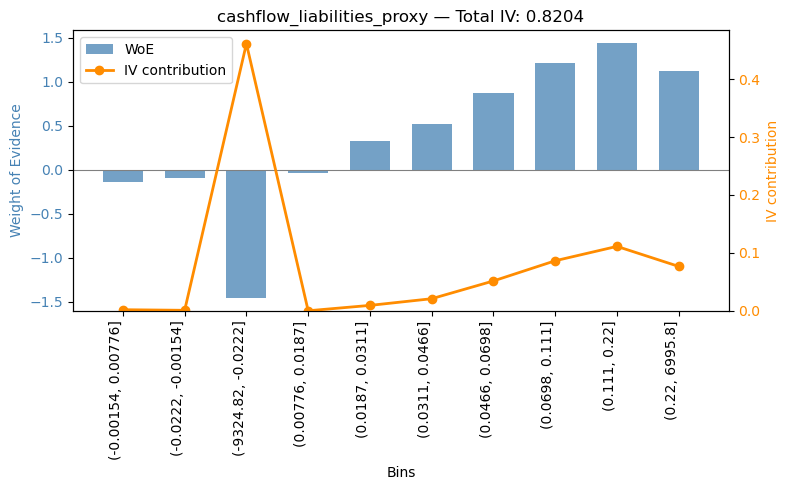

,bin,records,defaults,population (%),precision (%),recall (%),cumm_precision (%),cumm_recall (%),lift
0,"(-9324.82, -0.0222]",47539,2736,10.00%,5.76%,41.14%,5.76%,41.14%,4.114
1,"(-0.0222, -0.00154]",47539,730,10.00%,1.54%,10.98%,3.65%,52.12%,2.606
2,"(-0.00154, 0.00776]",47539,760,10.00%,1.60%,11.43%,2.96%,63.55%,2.118
3,"(0.00776, 0.0187]",47539,691,10.00%,1.45%,10.39%,2.59%,73.94%,1.848
4,"(0.0187, 0.0311]",47539,479,10.00%,1.01%,7.20%,2.27%,81.14%,1.623
5,"(0.0311, 0.0466]",47538,399,10.00%,0.84%,6.00%,2.03%,87.14%,1.452
6,"(0.0466, 0.0698]",47539,279,10.00%,0.59%,4.20%,1.83%,91.34%,1.305
7,"(0.0698, 0.111]",47539,199,10.00%,0.42%,2.99%,1.65%,94.33%,1.179
8,"(0.111, 0.22]",47539,159,10.00%,0.33%,2.39%,1.50%,96.72%,1.075
9,"(0.22, 6995.8]",47539,218,10.00%,0.46%,3.28%,1.40%,100.00%,1.000


Feature: roe, IV: 0.7876415534947192


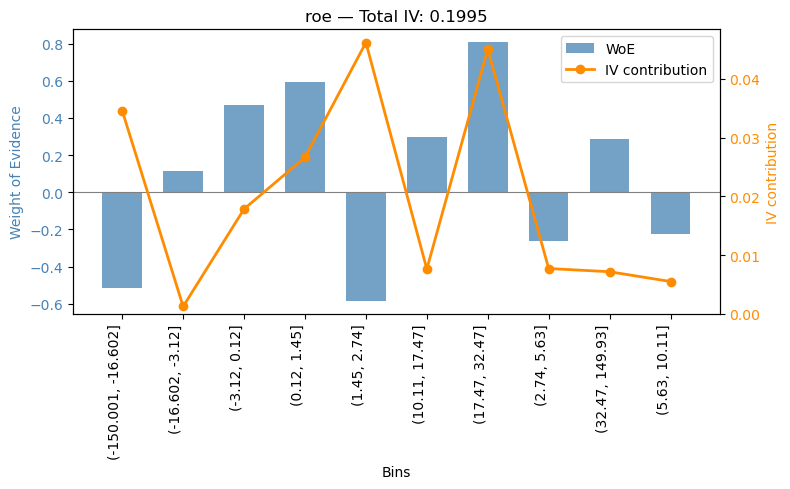

,bin,records,defaults,population (%),precision (%),recall (%),cumm_precision (%),cumm_recall (%),lift
0,"(-150.001, -16.602]",47539,1104,10.00%,2.32%,16.60%,2.32%,16.60%,1.660
1,"(-16.602, -3.12]",47571,594,10.01%,1.25%,8.93%,1.79%,25.53%,1.276
2,"(-3.12, 0.12]",47624,418,10.02%,0.88%,6.29%,1.48%,31.82%,1.060
3,"(0.12, 1.45]",47525,370,10.00%,0.78%,5.56%,1.31%,37.38%,0.934
4,"(1.45, 2.74]",47827,1187,10.06%,2.48%,17.85%,1.54%,55.23%,1.103
5,"(2.74, 5.63]",47148,853,9.92%,1.81%,12.83%,1.59%,68.06%,1.134
6,"(5.63, 10.11]",47572,828,10.01%,1.74%,12.45%,1.61%,80.51%,1.150
7,"(10.11, 17.47]",47511,496,9.99%,1.04%,7.46%,1.54%,87.97%,1.100
8,"(17.47, 32.47]",47536,299,10.00%,0.63%,4.50%,1.44%,92.47%,1.027
9,"(32.47, 149.93]",47536,501,10.00%,1.05%,7.53%,1.40%,100.00%,1.000


Feature: net_profit_assets, IV: 0.778038412590097


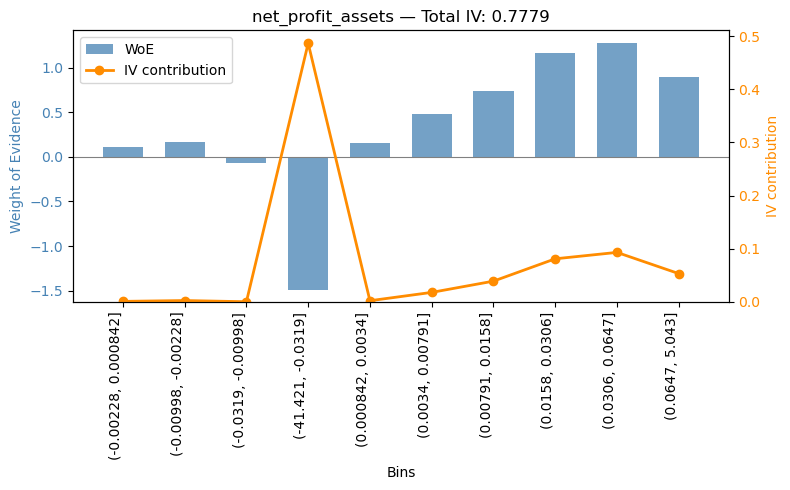

,bin,records,defaults,population (%),precision (%),recall (%),cumm_precision (%),cumm_recall (%),lift
0,"(-41.421, -0.0319]",47539,2809,10.00%,5.91%,42.24%,5.91%,42.24%,4.224
1,"(-0.0319, -0.00998]",47539,709,10.00%,1.49%,10.66%,3.70%,52.90%,2.645
2,"(-0.00998, -0.00228]",47539,562,10.00%,1.18%,8.45%,2.86%,61.35%,2.045
3,"(-0.00228, 0.000842]",47539,597,10.00%,1.26%,8.98%,2.46%,70.33%,1.758
4,"(0.000842, 0.0034]",47539,568,10.00%,1.19%,8.54%,2.21%,78.87%,1.577
5,"(0.0034, 0.00791]",47538,416,10.00%,0.88%,6.26%,1.98%,85.13%,1.419
6,"(0.00791, 0.0158]",47539,319,10.00%,0.67%,4.80%,1.80%,89.92%,1.285
7,"(0.0158, 0.0306]",47539,209,10.00%,0.44%,3.14%,1.63%,93.07%,1.163
8,"(0.0306, 0.0647]",47539,187,10.00%,0.39%,2.81%,1.49%,95.88%,1.065
9,"(0.0647, 5.043]",47539,274,10.00%,0.58%,4.12%,1.40%,100.00%,1.000


Feature: operating_cashflow_assets, IV: 0.7747245116514192


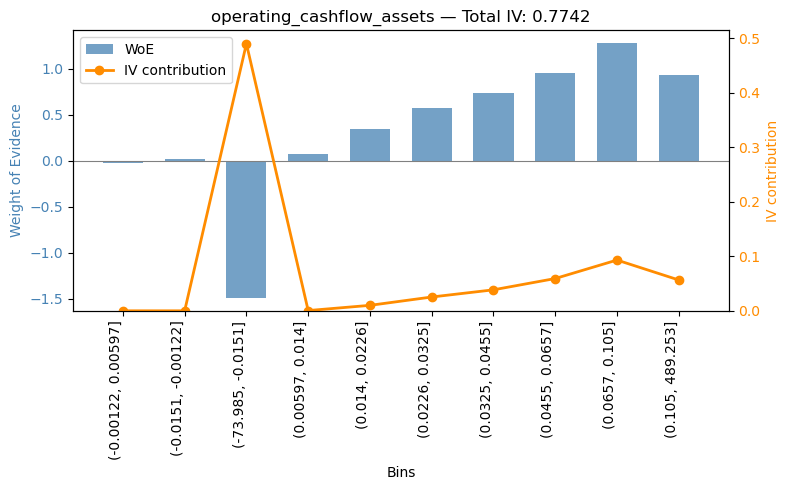

,bin,records,defaults,population (%),precision (%),recall (%),cumm_precision (%),cumm_recall (%),lift
0,"(-73.985, -0.0151]",47539,2820,10.00%,5.93%,42.41%,5.93%,42.41%,4.241
1,"(-0.0151, -0.00122]",47539,649,10.00%,1.37%,9.76%,3.65%,52.17%,2.608
2,"(-0.00122, 0.00597]",47539,683,10.00%,1.44%,10.27%,2.91%,62.44%,2.081
3,"(0.00597, 0.014]",47539,618,10.00%,1.30%,9.29%,2.51%,71.73%,1.793
4,"(0.014, 0.0226]",47539,473,10.00%,0.99%,7.11%,2.21%,78.84%,1.577
5,"(0.0226, 0.0325]",47538,376,10.00%,0.79%,5.65%,1.97%,84.50%,1.408
6,"(0.0325, 0.0455]",47539,321,10.00%,0.68%,4.83%,1.79%,89.32%,1.276
7,"(0.0455, 0.0657]",47539,258,10.00%,0.54%,3.88%,1.63%,93.20%,1.165
8,"(0.0657, 0.105]",47539,187,10.00%,0.39%,2.81%,1.49%,96.02%,1.067
9,"(0.105, 489.253]",47539,265,10.00%,0.56%,3.98%,1.40%,100.00%,1.000


Feature: liabilities_assets_proxy, IV: 0.6212417927236698


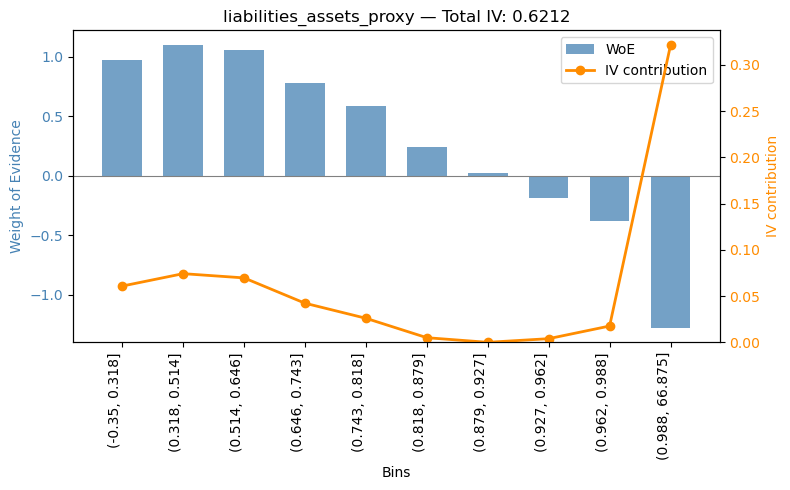

,bin,records,defaults,population (%),precision (%),recall (%),cumm_precision (%),cumm_recall (%),lift
0,"(-0.35, 0.318]",47539,254,10.00%,0.53%,3.82%,0.53%,3.82%,0.382
1,"(0.318, 0.514]",47539,223,10.00%,0.47%,3.35%,0.50%,7.17%,0.359
2,"(0.514, 0.646]",47539,233,10.00%,0.49%,3.50%,0.50%,10.68%,0.356
3,"(0.646, 0.743]",47539,308,10.00%,0.65%,4.63%,0.54%,15.31%,0.383
4,"(0.743, 0.818]",47539,373,10.00%,0.78%,5.61%,0.59%,20.92%,0.418
5,"(0.818, 0.879]",47538,526,10.00%,1.11%,7.91%,0.67%,28.83%,0.480
6,"(0.879, 0.927]",47539,653,10.00%,1.37%,9.82%,0.77%,38.65%,0.552
7,"(0.927, 0.962]",47539,802,10.00%,1.69%,12.06%,0.89%,50.71%,0.634
8,"(0.962, 0.988]",47539,968,10.00%,2.04%,14.56%,1.01%,65.26%,0.725
9,"(0.988, 66.875]",47539,2310,10.00%,4.86%,34.74%,1.40%,100.00%,1.000


Feature: equity_assets, IV: 0.6212405592543003


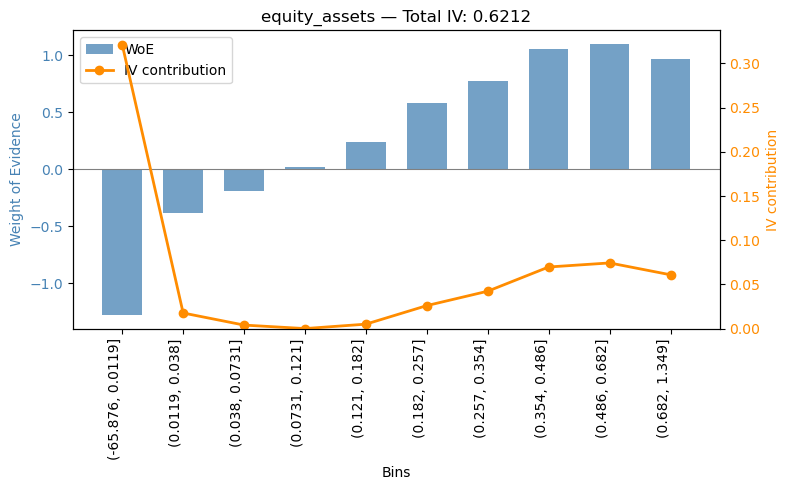

,bin,records,defaults,population (%),precision (%),recall (%),cumm_precision (%),cumm_recall (%),lift
0,"(-65.876, 0.0119]",47539,2310,10.00%,4.86%,34.74%,4.86%,34.74%,3.474
1,"(0.0119, 0.038]",47539,968,10.00%,2.04%,14.56%,3.45%,49.29%,2.465
2,"(0.038, 0.0731]",47539,802,10.00%,1.69%,12.06%,2.86%,61.35%,2.045
3,"(0.0731, 0.121]",47539,653,10.00%,1.37%,9.82%,2.49%,71.17%,1.779
4,"(0.121, 0.182]",47539,526,10.00%,1.11%,7.91%,2.21%,79.08%,1.582
5,"(0.182, 0.257]",47538,373,10.00%,0.78%,5.61%,1.97%,84.69%,1.412
6,"(0.257, 0.354]",47539,308,10.00%,0.65%,4.63%,1.79%,89.32%,1.276
7,"(0.354, 0.486]",47539,233,10.00%,0.49%,3.50%,1.62%,92.83%,1.160
8,"(0.486, 0.682]",47539,223,10.00%,0.47%,3.35%,1.49%,96.18%,1.069
9,"(0.682, 1.349]",47539,254,10.00%,0.53%,3.82%,1.40%,100.00%,1.000


Feature: operating_profit_assets, IV: 0.615308446499006


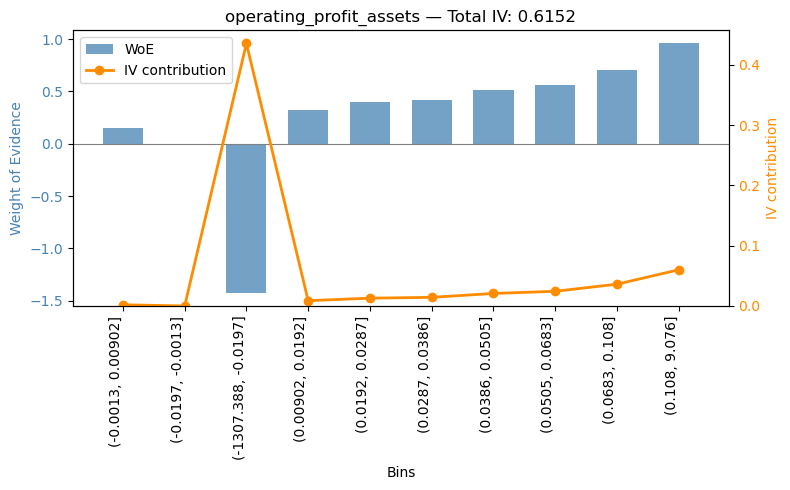

,bin,records,defaults,population (%),precision (%),recall (%),cumm_precision (%),cumm_recall (%),lift
0,"(-1307.388, -0.0197]",47539,2662,10.00%,5.60%,40.03%,5.60%,40.03%,4.003
1,"(-0.0197, -0.0013]",47539,671,10.00%,1.41%,10.09%,3.51%,50.12%,2.506
2,"(-0.0013, 0.00902]",47539,575,10.00%,1.21%,8.65%,2.74%,58.77%,1.959
3,"(0.00902, 0.0192]",47539,485,10.00%,1.02%,7.29%,2.31%,66.06%,1.652
4,"(0.0192, 0.0287]",47539,450,10.00%,0.95%,6.77%,2.04%,72.83%,1.457
5,"(0.0287, 0.0386]",47538,440,10.00%,0.93%,6.62%,1.85%,79.44%,1.324
6,"(0.0386, 0.0505]",47539,400,10.00%,0.84%,6.02%,1.71%,85.46%,1.221
7,"(0.0505, 0.0683]",47539,381,10.00%,0.80%,5.73%,1.59%,91.19%,1.140
8,"(0.0683, 0.108]",47539,330,10.00%,0.69%,4.96%,1.49%,96.15%,1.068
9,"(0.108, 9.076]",47539,256,10.00%,0.54%,3.85%,1.40%,100.00%,1.000


Feature: roa, IV: 0.614278805760833


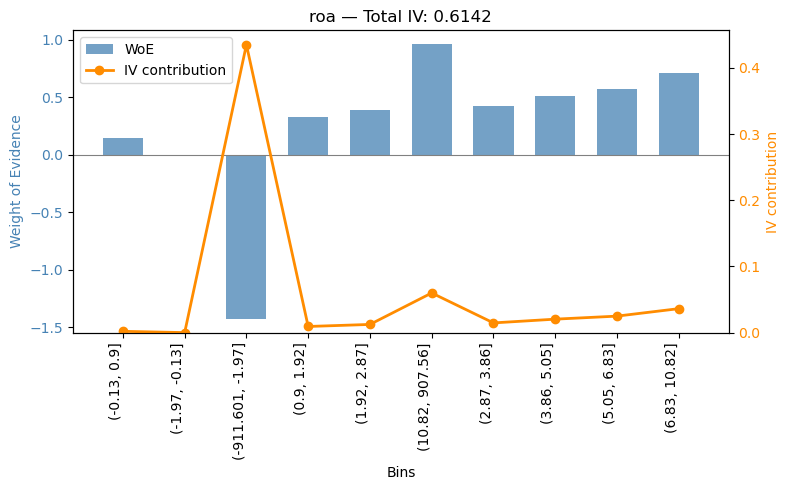

,bin,records,defaults,population (%),precision (%),recall (%),cumm_precision (%),cumm_recall (%),lift
0,"(-911.601, -1.97]",47625,2662,10.02%,5.59%,40.03%,5.59%,40.03%,3.996
1,"(-1.97, -0.13]",47761,673,10.05%,1.41%,10.12%,3.50%,50.15%,2.499
2,"(-0.13, 0.9]",47362,575,9.96%,1.21%,8.65%,2.74%,58.80%,1.958
3,"(0.9, 1.92]",47826,484,10.06%,1.01%,7.28%,2.31%,66.08%,1.648
4,"(1.92, 2.87]",47386,453,9.97%,0.96%,6.81%,2.04%,72.89%,1.456
5,"(2.87, 3.86]",47638,439,10.02%,0.92%,6.60%,1.85%,79.49%,1.323
6,"(3.86, 5.05]",47484,402,9.99%,0.85%,6.05%,1.71%,85.53%,1.221
7,"(5.05, 6.83]",47394,377,9.97%,0.80%,5.67%,1.59%,91.20%,1.140
8,"(6.83, 10.82]",47439,329,9.98%,0.69%,4.95%,1.49%,96.15%,1.068
9,"(10.82, 907.56]",47474,256,9.99%,0.54%,3.85%,1.40%,100.00%,1.000


Feature: interest_coverage_proxy, IV: 0.5555535041064982


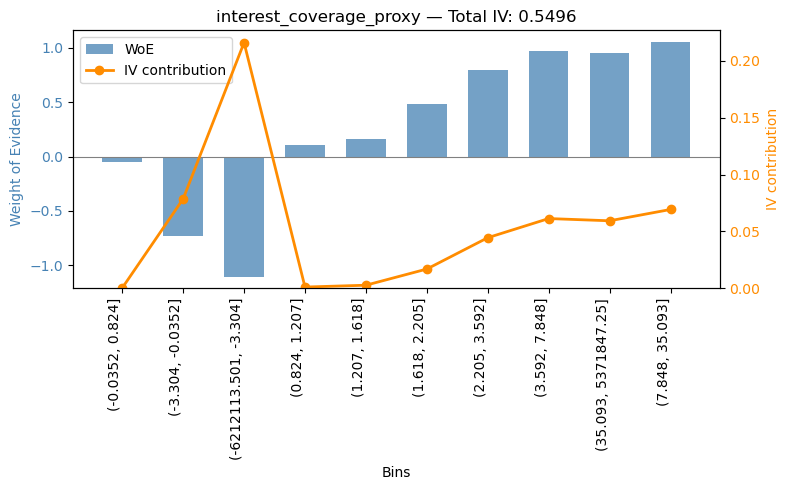

,bin,records,defaults,population (%),precision (%),recall (%),cumm_precision (%),cumm_recall (%),lift
0,"(-6212113.501, -3.304]",47539,1949,10.00%,4.10%,29.31%,4.10%,29.31%,2.931
1,"(-3.304, -0.0352]",47539,1366,10.00%,2.87%,20.54%,3.49%,49.85%,2.492
2,"(-0.0352, 0.824]",47539,696,10.00%,1.46%,10.47%,2.81%,60.32%,2.011
3,"(0.824, 1.207]",47539,600,10.00%,1.26%,9.02%,2.42%,69.34%,1.733
4,"(1.207, 1.618]",51605,615,10.86%,1.19%,9.25%,2.16%,78.59%,1.545
5,"(1.618, 2.205]",43472,378,9.14%,0.87%,5.68%,1.96%,84.27%,1.405
6,"(2.205, 3.592]",47539,301,10.00%,0.63%,4.53%,1.77%,88.80%,1.269
7,"(3.592, 7.848]",47539,253,10.00%,0.53%,3.80%,1.62%,92.60%,1.158
8,"(7.848, 35.093]",47539,234,10.00%,0.49%,3.52%,1.49%,96.12%,1.068
9,"(35.093, 5371847.25]",47539,258,10.00%,0.54%,3.88%,1.40%,100.00%,1.000


Feature: operating_margin, IV: 0.5070978756324289


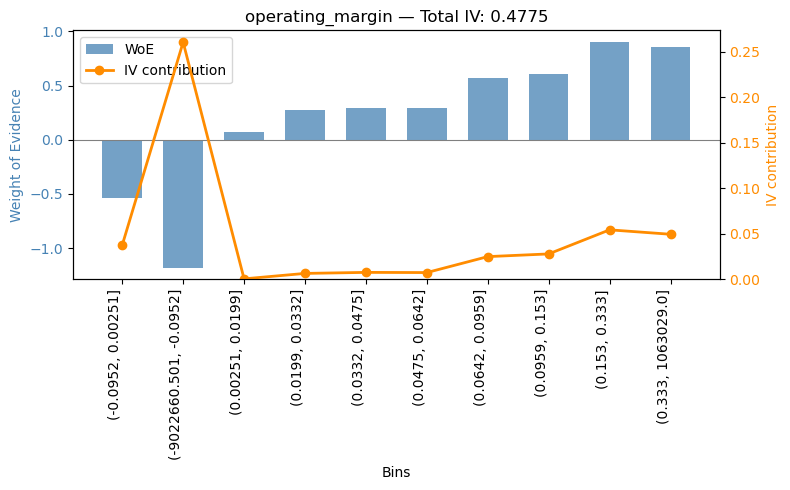

,bin,records,defaults,population (%),precision (%),recall (%),cumm_precision (%),cumm_recall (%),lift
0,"(-9022660.501, -0.0952]",47539,2108,10.00%,4.43%,31.70%,4.43%,31.70%,3.170
1,"(-0.0952, 0.00251]",47539,1125,10.00%,2.37%,16.92%,3.40%,48.62%,2.431
2,"(0.00251, 0.0199]",47539,617,10.00%,1.30%,9.28%,2.70%,57.89%,1.930
3,"(0.0199, 0.0332]",47539,508,10.00%,1.07%,7.64%,2.29%,65.53%,1.638
4,"(0.0332, 0.0475]",47539,496,10.00%,1.04%,7.46%,2.04%,72.99%,1.460
5,"(0.0475, 0.0642]",47538,498,10.00%,1.05%,7.49%,1.88%,80.48%,1.341
6,"(0.0642, 0.0959]",47539,378,10.00%,0.80%,5.68%,1.72%,86.17%,1.231
7,"(0.0959, 0.153]",47539,364,10.00%,0.77%,5.47%,1.60%,91.64%,1.145
8,"(0.153, 0.333]",47539,271,10.00%,0.57%,4.08%,1.49%,95.71%,1.063
9,"(0.333, 1063029.0]",47539,285,10.00%,0.60%,4.29%,1.40%,100.00%,1.000


In [19]:
for feats in suspicious_features['features']:
    print(f'Feature: {feats}, IV: {suspicious_features.query("features == @feats")["iv_train"].values[0]}')
    fig, axes = plot_woe_iv(iv_imputed_df.query('features == @feats')['iv_train_df'].values[0], feats, figsize=(8, 5))
    plt.show()
    display(precision_recall_by_bin(train_imputed, feats))

### Correlation (non-imputed) & (imputed)

In [20]:
def drop_corr_features(df, corr_feat_vars, threshold):
    corr_df = df[corr_feat_vars].corr()
    corr_pairs = corr_df.unstack()

    high_corr = corr_pairs[(abs(corr_pairs) > threshold) & (corr_pairs != 1.0)]
    high_corr = high_corr.drop_duplicates()
    print(high_corr)
    high_cor_vars = list(dict(high_corr).keys())
    print(high_cor_vars)

    # select the feature giving highest lift (precision per bin)
    def features_to_drop(corr_pairs):
        a, b = corr_pairs[0], corr_pairs[1]
        a_lift_bin = precision_recall_by_bin(train, a)['lift']
        b_lift_bin = precision_recall_by_bin(train, b)['lift']
        lift_diff = a_lift_bin - b_lift_bin
        for dist in lift_diff:
            if dist == 0: continue
            elif dist > 0: return b
            else: return a

    corr_feats_to_drop = [features_to_drop(corr_pairs) for corr_pairs in high_cor_vars]
    return corr_feats_to_drop

In [21]:
corr_feat_vars = [f for f in feature_vars if f not in categorical_features]

In [22]:
high_corr_vars = drop_corr_features(train, corr_feat_vars, 0.7)
high_corr_vars_imputed = drop_corr_features(train_imputed, corr_feat_vars, 0.7)

operating_profit_assets    roa                           1.000000
liabilities_assets_proxy   equity_assets                -1.000000
operating_cashflow_assets  cashflow_profit_gap_assets   -0.989565
dtype: float64
[('operating_profit_assets', 'roa'), ('liabilities_assets_proxy', 'equity_assets'), ('operating_cashflow_assets', 'cashflow_profit_gap_assets')]
liabilities_assets_proxy   equity_assets                -1.000000
operating_cashflow_assets  cashflow_profit_gap_assets   -0.989565
dtype: float64
[('liabilities_assets_proxy', 'equity_assets'), ('operating_cashflow_assets', 'cashflow_profit_gap_assets')]


### Save the final list of features
- Dropping the low IV features (less than 0.01)
- Keeping high IV features (IV >= 0.5)
- Dropping features with correlation more than 70%

In [23]:
final_features_to_drop = list(set(list(iv_df.query('iv_train < 0.01')['features']) + high_corr_vars))
final_features_imputed_to_drop = list(set(list(iv_imputed_df.query('iv_train < 0.01')['features']) + high_corr_vars_imputed))
print(len(final_features_to_drop),  len(final_features_imputed_to_drop))

8 7


In [24]:
pickle.dump({
    'final_features_to_drop': final_features_to_drop,
    'final_features_to_dropimputed': final_features_imputed_to_drop,
}, open('../Files/selected_features.csv', 'wb'))